# Probability and statistics for computational ML

## 1. Introduction and learning objectives

This chapter connects probability statements to arrays, likelihoods, and experimental evidence. After completing it you should distinguish a distribution from a sample, derive simple estimators, compute covariance with an explicit denominator, and describe what an uncertainty interval actually measures.

**Diagnostic:** attempt the first three exercises before reading further. If you can derive the posterior, calculate covariance, and explain the assumptions without the references, skim Sections 2–4 and complete the implementation and uncertainty checks. Elementary integration is assumed.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 00.02.01 — Update a rare-event belief

**Type:** Numerical · **Answer:** Markdown

A population has prevalence 0.10. A binary detector has sensitivity 0.80 and false-positive rate 0.10. Compute the probability of the condition given a positive result. Explain why sensitivity alone is not that probability.

**Expected outcome:** a normalized posterior with the evidence denominator shown.

**Your response to Exercise 00.02.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.01**

Partition positive results into true positives and false positives before dividing.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.01**

The joint probabilities are 0.10×0.80 = 0.08 and 0.90×0.10 = 0.09. Thus the positive-result probability is 0.17 and the posterior is 8/17, approximately 0.4706. Sensitivity conditions on the true condition; the requested posterior conditions on the observed result. The calculation assumes the stated rates apply to this population.

</details>

### Exercise 00.02.02 — Audit a covariance convention

**Type:** Numerical · **Answer:** Markdown

For rows X = [(0,1), (2,1), (4,4)], calculate the mean, centered cross-product sum, maximum-likelihood covariance, and unbiased sample covariance.

**Expected outcome:** two 2×2 covariance matrices with their denominators identified.

**Your response to Exercise 00.02.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.02**

Center each column. The cross-product sum is the transpose of the centered matrix multiplied by itself.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.02**

The mean is (2,2). Centered rows are (−2,−1), (0,−1), (2,2), giving cross-product sum [[8,6],[6,6]]. Dividing by n=3 gives [[8/3,2],[2,2]]. Dividing by n−1=2 gives [[4,3],[3,3]]. The latter is unbiased for population covariance under independent, identically distributed observations with finite second moments; it is not the Gaussian covariance MLE.

</details>

### Exercise 00.02.03 — Separate dependence from correlation

**Type:** Conceptual · **Answer:** Markdown

Let X be uniform on {−1,0,1} and Y=X². Find Cov(X,Y). Are the variables independent?

**Expected outcome:** a zero covariance calculation and a probability argument about dependence.

**Your response to Exercise 00.02.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.03**

Use symmetry to calculate E[X] and E[X³]. Then condition on X=0.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.03**

E[X]=E[X³]=0 and E[Y]=2/3, so Cov(X,Y)=E[X³]−E[X]E[Y]=0. Nevertheless P(Y=0 | X=0)=1 whereas P(Y=0)=1/3. Independence implies zero covariance when moments exist; the converse fails because covariance measures linear co-variation.

</details>

## 2. Prerequisites and mathematical foundations

Use capitals for random variables and lowercase for realized values. For discrete events, P(A | B)=P(A∩B)/P(B) when P(B)>0. The law of total probability expands an evidence probability over mutually exclusive, exhaustive hypotheses H_j. Bayes' rule is

$$P(H_j\mid E)=\frac{P(E\mid H_j)P(H_j)}{\sum_k P(E\mid H_k)P(H_k)}.$$

A discrete mass sums to one; a continuous density integrates to one. Density at a point is not a probability. For a narrow normal distribution the density can exceed one, while probabilities of intervals remain between zero and one. Conditioning a continuous variable is defined through conditional densities, not division by the zero probability of a single point.

Expectation is a weighted sum or integral. For finite second moments,

$$\operatorname{Cov}(X)=E[(X-\mu)(X-\mu)^T],\qquad
\operatorname{Var}(a^TX)=a^T\operatorname{Cov}(X)a.$$

Covariance is symmetric and positive semidefinite because a variance is nonnegative. A singular sample covariance can reflect redundant features or too few independent rows. Correlation divides covariance by standard deviations and is undefined for a constant variable.

## 3. Theoretical development and worked examples

### Distributions become objectives

For Y∼Bernoulli(p), P(Y=y)=p^y(1−p)^(1−y), E[Y]=p, and Var(Y)=p(1−p). A categorical distribution generalizes this to one mutually exclusive outcome among K classes with nonnegative probabilities summing to one. A normal N(μ,σ²) models a real quantity with mean μ and variance σ²; it does not make bounded or heavy-tailed data normal merely because a mean is calculated.

For iid observations, the joint likelihood is a product. A log transforms that product into a sum. For binary outcomes y_i, the **mean** negative log-likelihood is

$$L(p)=-\bar y\log p-(1-\bar y)\log(1-p),\qquad
\frac{dL}{dp}=\frac{p-\bar y}{p(1-p)}.$$

Its interior stationary point is p=ȳ. If all labels are zero or one, the MLE is at the boundary; the derivative formula above is only for 0 < p < 1. Logistic regression later constrains p using a real-valued logit. Multiplying the loss by n leaves an unregularized optimum unchanged but changes gradient scale and the strength of a separately added penalty.

For Gaussian rows x_i∈R^d with unknown mean and covariance, minimizing the joint negative log-likelihood gives μ̂=Σ_i x_i/n and Σ̂=Σ_i(x_i−μ̂)(x_i−μ̂)^T/n when the covariance estimate is nonsingular. Bessel's denominator n−1 instead corrects the downward bias caused by fitting the mean. Derive the scalar identity E[Σ_i(X_i−X̄)²]=(n−1)σ² by expanding around the population mean; the covariance result follows entry by entry.

### Estimation is conditional on a model

MLE maximizes data likelihood. MAP maximizes likelihood times a prior density, and a posterior mean averages over that posterior. For a Beta(α,β) prior and k successes in n trials, the posterior is Beta(α+k,β+n−k). Its mean is (α+k)/(α+β+n). Its mode is (α+k−1)/(α+β+n−2) only when both posterior shape parameters exceed one. These answer different questions.

### Exercise 00.02.04 — Compare three estimates

**Type:** Mathematical · **Answer:** Markdown

With one success in four trials and a Beta(2,2) prior, compute MLE, MAP, and posterior mean. Derive the interior MAP by differentiating the log posterior.

**Expected outcome:** three distinct estimates and the mode's domain condition.

**Your response to Exercise 00.02.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.04**

The powers of p and 1−p in the posterior are k+α−1 and n−k+β−1.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.04**

MLE=1/4. The posterior is Beta(3,5), so its mean is 3/8. Setting 2/p−4/(1−p)=0 gives MAP=1/3. Both posterior shape parameters exceed one, so this stationary point is the interior mode. The prior changes the objective; averaging the posterior is not equivalent to maximizing it.

</details>

## 4. Guided exercises

For iid Bernoulli samples of size n, Var(Ȳ)=p(1−p)/n. Independence removes cross-covariances in the variance of the sum. Correlated observations can make this formula substantially overconfident. An approximate normal interval Ȳ±1.96√(Ȳ(1−Ȳ)/n) is not reliable for small samples or probabilities close to the boundaries. It can even extend outside [0,1].

A percentile bootstrap resamples observed rows with replacement, recomputes a statistic, and uses empirical quantiles. It approximates repeated sampling using the empirical distribution. It does not automatically handle time dependence, clustered observations, selection bias, or statistics at boundaries. A 95% frequentist procedure refers to repeated-sample coverage under assumptions; it is not a 95% posterior probability for a fixed parameter.

### Exercise 00.02.05 — Derive the variance of a sample mean

**Type:** Mathematical · **Answer:** Markdown

Derive Var(X̄) for n iid observations with variance σ². State what additional terms appear without independence.

**Expected outcome:** the 1/n variance reduction and the missing covariance terms.

**Your response to Exercise 00.02.05**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.05**

Expand the variance of a sum before dividing by n².

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.05**

Var(X̄)=n⁻²Σ_iΣ_j Cov(X_i,X_j). Under independence the off-diagonal terms vanish, leaving nσ²/n²=σ²/n. Otherwise the additional contribution is 2n⁻²Σ_(i < j)Cov(X_i,X_j). Identical marginal variances alone do not justify an iid interval or an ordinary row bootstrap.

</details>

## 5. Implementation challenges

### Exercise 00.02.06 — Normalize a discrete posterior

**Type:** Programming · **Answer:** Code

Implement `discrete_posterior(prior, likelihood)`. Inputs are equally sized finite one-dimensional vectors: a normalized prior and event probabilities in [0,1]. Reject zero evidence. Return posterior and evidence, without mutating either input.

**Expected outcome:** the rare-event example and a zero-evidence failure check.

In [ ]:
# Your code for Exercise 00.02.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.06**

Check the input contract before multiplying elementwise and normalizing.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.06**

The evidence is a scalar normalizer, not the sum of likelihoods alone. This implementation intentionally covers event probabilities, not arbitrary continuous density values.

~~~python
def discrete_posterior(prior, likelihood):
    p, q = np.asarray(prior, dtype=float), np.asarray(likelihood, dtype=float)
    if p.ndim != 1 or p.size == 0 or q.shape != p.shape:
        raise ValueError("expected equal nonempty vectors")
    if not np.isfinite(p).all() or not np.isfinite(q).all():
        raise ValueError("finite probabilities required")
    if np.any(p < 0) or not np.isclose(p.sum(), 1) or np.any((q < 0) | (q > 1)):
        raise ValueError("invalid probability distribution")
    joint = p * q
    evidence = float(joint.sum())
    if evidence <= 0:
        raise ValueError("conditioning event has zero evidence")
    return joint / evidence, evidence
~~~

</details>

### Exercise 00.02.07 — Estimate covariance explicitly

**Type:** Programming · **Answer:** Code

Implement `sample_covariance(X, ddof=1)` for finite (n,d) rows with d≥1 and ddof either 0 or 1. Return mean and covariance. Require n>ddof. Compare with an independent library calculation using the same convention.

**Expected outcome:** both matrices from the diagnostic, including the one-feature shape (1,1).

In [ ]:
# Your code for Exercise 00.02.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.07**

Use centered.T @ centered; never let a one-dimensional covariance silently become a scalar.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.07**

The observation axis is zero. The matrix product handles one or many features consistently. NumPy's `np.cov(X, rowvar=False, ddof=ddof)` is a useful independent check, with a scalar result promoted for d=1.

~~~python
def sample_covariance(X, ddof=1):
    X = np.asarray(X, dtype=float)
    if ddof not in (0, 1) or X.ndim != 2 or X.shape[1] == 0 or len(X) <= ddof:
        raise ValueError("expected rows with n > ddof and ddof in {0,1}")
    if not np.isfinite(X).all():
        raise ValueError("finite observations required")
    mean = X.mean(axis=0)
    centered = X - mean
    return mean, centered.T @ centered / (len(X) - ddof)
~~~

</details>

### Exercise 00.02.08 — Differentiate a Bernoulli likelihood

**Type:** Programming · **Answer:** Code

Implement `bernoulli_nll(p, y)` returning mean negative log-likelihood and derivative with respect to scalar p. Restrict p to the open interval (0,1) and y to a nonempty binary vector. Check the derivative by perturbing p in an independently written objective.

**Expected outcome:** finite-difference agreement at p=.25, .55, .8, away from boundaries.

In [ ]:
# Your code for Exercise 00.02.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.08**

Use log1p(−p) for log(1−p). The derivative is for a mean objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.08**

The explicit interior domain avoids evaluating undefined logarithms. Boundary MLEs remain mathematically meaningful as limits, but belong to a separate API contract. A derivative check must not reuse this function's returned loss as its only oracle.

~~~python
def bernoulli_nll(p, y):
    y = np.asarray(y, dtype=float)
    if np.ndim(p) != 0 or not np.isfinite(p) or not 0 < p < 1:
        raise ValueError("p must be a finite interior scalar")
    if y.ndim != 1 or y.size == 0 or not np.isin(y, [0, 1]).all():
        raise ValueError("nonempty binary vector required")
    average = float(y.mean())
    loss = -average * np.log(p) - (1 - average) * np.log1p(-p)
    return float(loss), float((p - average) / (p * (1 - p)))
~~~

</details>

### Exercise 00.02.09 — Bootstrap a mean with bounded memory

**Type:** Programming · **Answer:** Code

Implement `bootstrap_mean_interval(values, repeats=500, level=.95, seed=0)`. Return the sample mean, percentile interval, and resampled means. Allocate one resample at a time. Require at least two observations and two repeats.

**Expected outcome:** reproducible endpoints for the same seed, and an explicit explanation of what is being resampled.

In [ ]:
# Your code for Exercise 00.02.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.09**

Preallocate a vector of repeats estimates instead of a repeats×n sample matrix.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.09**

This resamples iid scalar observations, treating the empirical distribution as the population proxy. It uses O(n+repeats) working storage. Reproducibility does not establish interval coverage.

~~~python
def bootstrap_mean_interval(values, repeats=500, level=.95, seed=0):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or values.size < 2 or not np.isfinite(values).all():
        raise ValueError("at least two finite scalar observations required")
    if not isinstance(repeats, (int, np.integer)) or repeats < 2 or not 0 < level < 1:
        raise ValueError("invalid bootstrap configuration")
    rng = np.random.default_rng(seed)
    estimates = np.empty(repeats)
    for j in range(repeats):
        estimates[j] = values[rng.integers(0, len(values), len(values))].mean()
    tail = (1 - level) / 2
    interval = np.quantile(estimates, [tail, 1 - tail])
    return float(values.mean()), interval, estimates
~~~

</details>

## 6. Experiments and visualizations

The demonstration plots the variance formula and actual sample means. The curve is a theoretical reference, not measured coverage of an interval procedure.

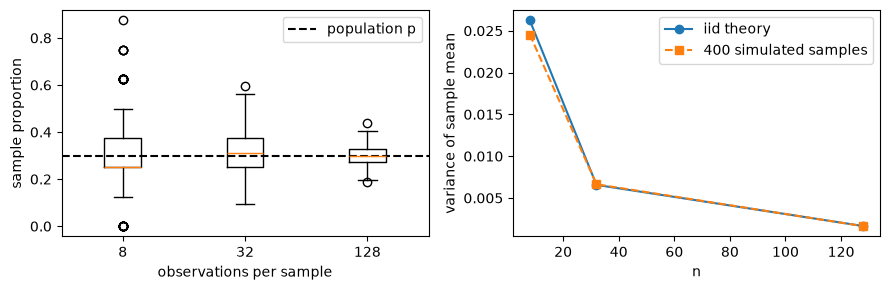

In [2]:
rng = np.random.default_rng(2026)
sizes = np.array([8, 32, 128])
means = [rng.binomial(n, .3, size=400) / n for n in sizes]
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].boxplot(means, tick_labels=[str(n) for n in sizes])
axes[0].axhline(.3, color="black", linestyle="--", label="population p")
axes[0].set(xlabel="observations per sample", ylabel="sample proportion")
axes[0].legend()
axes[1].plot(sizes, [.3 * .7 / n for n in sizes], "o-", label="iid theory")
axes[1].plot(sizes, [np.var(m, ddof=1) for m in means], "s--", label="400 simulated samples")
axes[1].set(xlabel="n", ylabel="variance of sample mean")
axes[1].legend()
fig.tight_layout()
plt.show()

### Exercise 00.02.10 — Investigate sampling variability

**Type:** Experimental · **Answer:** Code

Repeat the sample-mean experiment with p=.1 and sample sizes 10, 40, 160. Use 600 independent samples per size. Plot empirical variance against p(1−p)/n; repeat with a second seed.

**Expected outcome:** actual estimates, seeds, and a discussion of Monte Carlo variation; no demand for exact equality.

In [ ]:
# Your code for Exercise 00.02.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.10**

Binomial draws generate counts directly without storing all individual trials.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.10**

The following records an experiment rather than asserting a predetermined outcome. Compare the ratio with one, remembering that 600 replicates still introduce sampling error. A changed seed changes those errors.

~~~python
for seed in (11, 12):
    rng = np.random.default_rng(seed)
    sizes = np.array([10, 40, 160])
    observed = np.array([np.var(rng.binomial(n, .1, 600) / n, ddof=1) for n in sizes])
    expected = .1 * .9 / sizes
    print(seed, np.column_stack([sizes, observed, expected, observed / expected]))
    plt.plot(sizes, observed, "o-", label=f"seed {seed}")
plt.plot(sizes, expected, "k--", label="iid expectation")
plt.xlabel("sample size"); plt.ylabel("variance of sample mean"); plt.legend(); plt.show()
~~~

</details>

### Exercise 00.02.11 — Inspect a skewed bootstrap distribution

**Type:** Experimental · **Answer:** Code

Generate 30 lognormal observations with seed 22. Use the bootstrap implementation to display its mean distribution and 95% interval. Discuss asymmetry, outliers, and the iid assumption.

**Expected outcome:** a reproducible plot and a conditional interpretation, without claiming demonstrated 95% coverage.

In [ ]:
# Your code for Exercise 00.02.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.11**

Use the returned bootstrap estimates; interval endpoints alone hide the distribution's shape.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.11**

This depends on `bootstrap_mean_interval` above. A lognormal sample is a stress case for a small-sample symmetric approximation. Repeatedly drawing new datasets and measuring coverage would be a different experiment.

~~~python
values = np.random.default_rng(22).lognormal(size=30)
mean, interval, estimates = bootstrap_mean_interval(values, repeats=800, seed=23)
print("sample mean and percentile interval", mean, interval)
plt.hist(estimates, bins=25)
for point in interval:
    plt.axvline(point, color="red", linestyle="--")
plt.xlabel("resampled mean"); plt.ylabel("count"); plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 00.02.12 — Diagnose false certainty

**Type:** Critical · **Answer:** Markdown

A held-out set has no observed positive cases. Resampling its labels yields a zero-width interval for prevalence. Another analyst bootstraps fixed model predictions and says the interval includes all training uncertainty. Evaluate both claims.

**Expected outcome:** explain the empirical distribution's support and distinguish conditional evaluation uncertainty from refitting variability.

**Your response to Exercise 00.02.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.12**

A row bootstrap cannot generate a category absent from the empirical sample, and fixed predictions do not retrain a model.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.12**

The zero-width interval describes an impoverished empirical distribution, not proof of zero population prevalence. A different interval construction or additional data is needed for that boundary problem. Resampling held-out label/prediction pairs conditions on the trained model and the sampling scheme; it omits training-set and model-selection variation. Nested refitting can study those sources, at additional cost and with its own assumptions.

</details>

## 8. Review questions and knowledge checks

### Exercise 00.02.13 — Audit an iid likelihood

**Type:** Conceptual · **Answer:** Markdown

A dataset contains ten measurements from each of 20 people. Is multiplying 200 marginal densities automatically a justified joint likelihood? How should an uncertainty experiment reflect the sampling unit?

**Expected outcome:** name the independence assumption and propose a participant-level alternative.

**Your response to Exercise 00.02.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.02.13**

Repeated observations from one person may share latent causes.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.02.13**

The product is a joint likelihood only if the specified conditional independence assumptions hold. Within-person correlation often violates a marginal iid model. A hierarchical model can express that structure, and a participant-level split or cluster bootstrap can preserve it during evaluation. More rows do not automatically mean 200 independent pieces of evidence.

</details>

## 9. Summary and next learning steps

You have connected distribution assumptions to estimation, derivatives, covariance, and uncertainty. Before advancing, explain a posterior normalization; implement and independently verify a likelihood derivative and both covariance conventions; evaluate when iid uncertainty fails.

Continue with [numerical computing](numerical-computing.ipynb), then the [mathematical audit](../../projects/00-mathematical-audit/mathematical-audit.ipynb). Targeted reference: [NumPy covariance conventions](https://numpy.org/doc/stable/reference/generated/numpy.cov.html). The Stage 01 evaluation chapter revisits uncertainty for a fixed fitted model.